# Linear Algebra Review and SciPy Basics

Definitions and notation in this review follow Section **2.2 Vectors and Matrices** in Biegler (2010), with the invertibility discussion cross-checked against Lay, *Linear Algebra and Its Applications*, 3rd ed.

**Recommended Links**
* [NumPy Documentation - Main Page](https://docs.scipy.org/doc/numpy-1.15.0/reference/)
* [SciPy Documentation - Main Page](https://docs.scipy.org/doc/scipy-1.1.0/reference/)
* [SciPy Linear Algebra - Tutorial](https://docs.scipy.org/doc/scipy-1.1.0/reference/tutorial/linalg.html)
* [SciPy Linear Algebra - API](https://docs.scipy.org/doc/scipy-1.1.0/reference/linalg.html)
* [SciPy Lecture Notes](http://www.scipy-lectures.org/) (Especially 1.1 - 1.6 for everyone and 2.1 - 2.2 for advanced users)

Tip: We will mostly use SciPy for linear algebra. (It has more sophisticated capabilities than NumPy.) We will use NumPy if/when SciPy does not offer a specific command.

This guide supplies definitions, proof details, and extended calculations for the lecture. Use the sections on [spaces and rank](#la-spaces), [worked factorizations](#la-factorizations), [SVD](#la-svd), and [conditioning](#la-conditioning) alongside the shorter handout. [Numerical Errors](Numerical-Errors.ipynb) computes roundoff and error measurements. The [scaling example](#ctx-scaling) returns scaled variables to their original units.


```{warning}
**AI-drafted prose, not yet reviewed by Prof. Dowling.**

Some of the writing on this page was drafted or edited by an AI assistant and has not yet been reviewed: 21 rewritten and 13 added markdown cells, measured against the last version of this notebook predating AI editing (2026-08-17).

This notice is about the *prose only*. It says nothing either way about the code, the numbers or the figures, which are checked separately. It is removed once the page has been reviewed.
```

In [1]:
# Load required Python libraries.
import numpy as np
from scipy import linalg

# Seed the random number generator so this notebook is reproducible
# (Pyomo style guide, section 8).
np.random.seed(0)

## Notation and linear maps

Scalars and scalar components are plain, vectors are bold lower case, and matrices are bold upper case: $\alpha$, $x_i$, $\mathbf{x}$, $A_{ij}$, and $\mathbf{A}$. The matrix $\mathbf{A}\in\mathbb{R}^{n\times m}$ represents the **linear map** $T:\mathbb{R}^m\to\mathbb{R}^n$, $T(\mathbf{x})=\mathbf{Ax}$. Linearity means

$$T(\alpha\mathbf{x}+\beta\mathbf{y})=\alpha T(\mathbf{x})+\beta T(\mathbf{y})$$

for every $\mathbf{x},\mathbf{y}\in\mathbb{R}^m$ and $\alpha,\beta\in\mathbb{R}$. The columns of $\mathbf{A}$ are the images of the coordinate vectors: $\mathbf{A}\mathbf{e}_j=\mathbf{a}_j$.

## Matrix operations

For $\mathbf{B}\in\mathbb{R}^{m\times p}$, $\mathbf{C}=\mathbf{AB}\in\mathbb{R}^{n\times p}$ has entries

$$C_{ij}=\sum_{k=1}^{m}A_{ik}B_{kj}.$$

The inner dimensions must match. Multiplication composes maps: first apply $\mathbf{B}$, then $\mathbf{A}$. If $\mathbf{A}$ is $4\times3$ and $\mathbf{B}$ is $3\times7$, $\mathbf{AB}$ is $4\times7$; $\mathbf{BA}$ is undefined because its inner dimensions are $7$ and $4$.

The transpose interchanges rows and columns, $(\mathbf{A}^\mathsf{T})_{ij}=A_{ji}$. A square matrix is **symmetric** when $\mathbf{A}=\mathbf{A}^\mathsf{T}$ and **diagonal** when $A_{ij}=0$ for $i\ne j$. The identity has $I_{ii}=1$ and all off-diagonal entries zero.

![The columns of a matrix give the images of the two coordinate directions; the unit square becomes a parallelogram.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-matrix-map.png)

For the illustrated $\mathbf{A}=\left[\begin{smallmatrix}1.5&.5\\.5&1\end{smallmatrix}\right]$, the area changes by $\det\mathbf{A}=1.25$. A negative determinant reverses orientation; a zero determinant collapses area to zero.

Video: 3Blue1Brown, [Linear transformations and matrices](https://www.3blue1brown.com/lessons/linear-transformations) and [Matrix multiplication as composition](https://www.3blue1brown.com/lessons/matrix-multiplication).

In [2]:
# Generate random matrices
n = 2
m = 3

Ao = np.random.rand(n, m)
Bo = np.random.rand(m, n)

print("Ao = ")
print(Ao)
print("\nBo = ")
print(Bo)


# What is the dimension of A*B? Try to answer this without the computer.

# Calculate A*B using Python
print("\nAo*Bo =")
print(Ao.dot(Bo))

Ao = 
[[0.5488135  0.71518937 0.60276338]
 [0.54488318 0.4236548  0.64589411]]

Bo = 
[[0.43758721 0.891773  ]
 [0.96366276 0.38344152]
 [0.79172504 0.52889492]]

Ao*Bo =
[[1.40657799 1.08244885]
 [1.15806481 0.98996907]]


**Activity**
* Calculate $\mathbf{A}_o^{T}$
* Create a square matrix and check if it is symmetric
* Create a 3x3 identity matrix

In [3]:
# Transpose
print("transpose(Ao) = \n", Ao.transpose(), "\n")

# Create a square matrix. Is it symmetric?

# Identify matrix
print("I = \n", np.identity(3), "\n")

transpose(Ao) = 
 [[0.5488135  0.54488318]
 [0.71518937 0.4236548 ]
 [0.60276338 0.64589411]] 

I = 
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 



## Determinant

For a square matrix $\mathbf{A}\in\mathbb{R}^{n\times n}$, expansion along any row $i$ gives

$$\det(\mathbf{A})=\sum_{j=1}^{n}(-1)^{i+j}A_{ij}\,\bar A_{ij},$$

where $A_{ij}$ is the entry in row $i$ and column $j$, and $\bar A_{ij}$ is the determinant of the $(n-1)\times(n-1)$ matrix obtained by deleting row $i$ and column $j$ from $\mathbf{A}$. Useful properties are

$$\begin{aligned}
\det(\mathbf{AB})&=\det(\mathbf{A})\det(\mathbf{B}),&\det(\mathbf{A}^\mathsf{T})&=\det(\mathbf{A}),\\
\det(\alpha\mathbf{A})&=\alpha^n\det(\mathbf{A}),&\det(\mathbf{I})&=1.
\end{aligned}$$

The exponent $n$ in the scaling law matters: multiplying the whole matrix by $\alpha$ scales each of its $n$ rows. A square matrix is singular exactly when $\det(\mathbf{A})=0$.

In [4]:
# Generate random matrices
nd = 2

Ad = np.random.rand(nd, nd)
Bd = np.random.rand(nd, nd)

Cd = np.array([(1, 0, 0), (-2, 0, 0), (0, 1, 1)])

print("Ad = ")
print(Ad)
print("\nBd = ")
print(Bd)
print("\nCd = ")
print(Cd)

Ad = 
[[0.56804456 0.92559664]
 [0.07103606 0.0871293 ]]

Bd = 
[[0.0202184  0.83261985]
 [0.77815675 0.87001215]]

Cd = 
[[ 1  0  0]
 [-2  0  0]
 [ 0  1  1]]


**Activity**
* Verify the properties listed under *Some properties for the determinant include*
* Are $\mathbf{A}_d$, $\mathbf{B}_d$ or $\mathbf{C}_d$ singular?

In [5]:
# Property 1
print("det(A*B) = ", linalg.det(Ad.dot(Bd)))

print("det(A)*det(B) = ", linalg.det(Ad) * linalg.det(Bd))

det(A*B) =  0.010247347495272154
det(A)*det(B) =  0.010247347495272162


In [6]:
# Property 2

In [7]:
# Property 3

In [8]:
# Property 4

**Another Example** (for at home)

Expand along the first row of

$$\mathbf{A}=\begin{bmatrix}1&5&0\\2&4&-1\\0&-2&0\end{bmatrix}.$$

Then

$$\det(\mathbf{A})=1\det\begin{bmatrix}4&-1\\-2&0\end{bmatrix}-5\det\begin{bmatrix}2&-1\\0&0\end{bmatrix}+0\det\begin{bmatrix}2&4\\0&-2\end{bmatrix}=-2.$$



(la-spaces)=
## Span, independence, and rank

A **linear combination** of $\mathbf{a}_1,\ldots,\mathbf{a}_m\in\mathbb{R}^n$ is $\sum_{j=1}^m\alpha_j\mathbf{a}_j$, with real coefficients. Their **span** is the set of all such combinations. They are **linearly independent** if $\sum_j\alpha_j\mathbf{a}_j=\mathbf{0}$ implies $\alpha_j=0$ for every $j$; otherwise they are dependent.

A **subspace** $S\subseteq\mathbb{R}^n$ contains $\mathbf{0}$ and is closed under linear combinations: $\alpha\mathbf{x}+\beta\mathbf{y}\in S$ for all $\mathbf{x},\mathbf{y}\in S$ and all real $\alpha,\beta$. A **basis** of $S$ is a linearly independent spanning set. Its number of vectors is $\dim S$. The zero subspace has the empty basis and dimension zero.

![Two independent vectors span a plane; dependent vectors span a line.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-span-basis.png)

For $\mathbf{A}\in\mathbb{R}^{n\times m}$, the **range** or **column space** is

$$\operatorname{Range}(\mathbf{A})=\{\mathbf{Ax}:\mathbf{x}\in\mathbb{R}^m\}=\operatorname{span}\{\mathbf{a}_1,\ldots,\mathbf{a}_m\}.$$

The **null space** is $\operatorname{Null}(\mathbf{A})=\{\mathbf{x}\in\mathbb{R}^m:\mathbf{Ax}=\mathbf{0}\}$. Both are subspaces, but they belong to different spaces: range in $\mathbb{R}^n$, null space in $\mathbb{R}^m$.

The **rank** $r(\mathbf{A})$ is the dimension of the column space, equivalently the row space or the size of the largest square submatrix with nonzero determinant. Full column rank means $r=m$; full row rank means $r=n$. Full rank means $r=\min(n,m)$; otherwise the matrix is rank deficient.

### Rank-nullity: complete a basis

Let $\mathbf{v}_1,\ldots,\mathbf{v}_k$ be a basis of the null space, and extend it to a basis $\mathbf{v}_1,\ldots,\mathbf{v}_m$ of the domain. Every $\mathbf{Ax}$ is a linear combination of $\mathbf{A}\mathbf{v}_{k+1},\ldots,\mathbf{A}\mathbf{v}_m$, because the first $k$ vectors map to zero. These remaining images are independent: any combination mapping to zero would be both a combination of the last basis vectors and a member of the span of the first $k$. Independence of the whole basis forces every coefficient to vanish. Thus

$$r(\mathbf{A})+\dim\operatorname{Null}(\mathbf{A})=m.$$

![A rank-one map sends the plane onto a line. Inputs differing by a null-space vector have the same image.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-col-null-space.png)

For the illustrated matrix $\left[\begin{smallmatrix}.5&1\\.5&1\end{smallmatrix}\right]$, the range is $\operatorname{span}\{(1,1)^\mathsf{T}\}$ and the null space is $\operatorname{span}\{(2,-1)^\mathsf{T}\}$. Both have dimension one. If $\mathbf{x}_0$ solves $\mathbf{Ax}=\mathbf{b}$, every solution is $\mathbf{x}_0+\mathbf{z}$ with $\mathbf{z}\in\operatorname{Null}(\mathbf{A})$. If $\mathbf{b}$ is outside the range, there is no solution.

Video: 3Blue1Brown, [Linear combinations, span, and basis vectors](https://www.3blue1brown.com/lessons/span), and [Inverse matrices, column space, and null space](https://www.3blue1brown.com/lessons/inverse-matrices).

**Activity.** Predict the ranks of $\mathbf{A}_o^\mathsf{T}$, $\mathbf{B}_o^\mathsf{T}$, $\mathbf{A}_d$, $\mathbf{B}_d$, and $\mathbf{C}_d$. Compare with `np.linalg.matrix_rank` and explain any rank deficiency in terms of dependent columns.

In [9]:
print("rank(A_o) = ", np.linalg.matrix_rank(Ao), "\n")

# Fill in remainder here.

rank(A_o) =  2 



## Inverse

A square matrix $\mathbf{A}$ is invertible when there is a matrix $\mathbf{A}^{-1}$ satisfying $\mathbf{AA}^{-1}=\mathbf{A}^{-1}\mathbf{A}=\mathbf{I}$. Then $\mathbf{Ax}=\mathbf{b}$ has the unique solution $\mathbf{x}=\mathbf{A}^{-1}\mathbf{b}$, although numerical software should solve the system directly rather than form the inverse. Also, $\det(\mathbf{A}^{-1})=1/\det(\mathbf{A})$. An orthogonal matrix $\mathbf{Q}$ satisfies $\mathbf{Q}^{-1}=\mathbf{Q}^\mathsf{T}$.

**Activity**
1. Calculate the inverse of the square matrix $\mathbf{A}_d$ and verify that $\mathbf{A}_d^{-1} \mathbf{A}_d = \mathbf{I}$. (The rectangular matrix $\mathbf{A}_o$ has no two-sided inverse.)
2. Verify that $\det(\mathbf{A}_d^{-1}) = 1/\det(\mathbf{A}_d)$
3. Is $\mathbf{Q}$ an orthogonal matrix?

![An invertible linear map can be undone; a collapsed direction cannot be recovered.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-inverse-map.png)

If $\det\mathbf{A}=0$ and an inverse existed, multiplicativity of the determinant would give $1=\det\mathbf{I}=\det(\mathbf{AA}^{-1})=\det\mathbf{A}\det\mathbf{A}^{-1}=0$, a contradiction. The [Invertible Matrix Theorem](#la-invertibility) collects the converse and equivalent conditions.

For dense unstructured matrices, factorizing and solving usually takes less work than explicitly forming an inverse and multiplying. Leading operation counts for a single right-hand side are approximately $2n^3/3$ for elimination versus $2n^3$ for an inverse. Accuracy also depends on the algorithm and data; avoid treating a computed inverse as a universal cure for a difficult solve. See Higham (2002), §14.1, p.260.


In [10]:
# Task 1

# Task 2

# Task 3
# Is this an orthogonal matrix? Yes, no, or need more information?
theta = 0.2
Q = np.array([(np.cos(theta), -np.sin(theta)), (np.sin(theta), np.cos(theta))])

print("Q = ")
print(Q)

Q = 
[[ 0.98006658 -0.19866933]
 [ 0.19866933  0.98006658]]


## Solving Linear Systems
Consider the linear system $\mathbf{A}_l \mathbf{x} = b_l$

In [11]:
Al = np.array([(4, 3), (6, 3)])
bl = np.array([1, 0])
print("Al = \n", Al)
print("\nbl = \n", bl)

Al = 
 [[4 3]
 [6 3]]

bl = 
 [1 0]


### Explicit Inverse

Calculate $\mathbf{x}$ by explicitly using $\mathbf{A}_l^{-1}$. Hint: Use linalg.inv().

In [12]:
Ainv = linalg.inv(Al)
print("Ainv = \n", Ainv, "\n")

# Now calculate and print x

Ainv = 
 [[-0.5         0.5       ]
 [ 1.         -0.66666667]] 



### LU Decomposition

Perform LU decomposition on $\mathbf{A}_l$. What structures do the $\mathbf{P}$, $\mathbf{L}$, and $\mathbf{U}$ matrices have?

![The permutation, unit lower-triangular, and upper-triangular factors in the SciPy convention.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-plu-structure.png)

SciPy returns $\mathbf{A}=\mathbf{PLU}$, so the solve is $\mathbf{Ly}=\mathbf{P}^\mathsf{T}\mathbf{b}$ followed by $\mathbf{Ux}=\mathbf{y}$. A permutation is orthogonal: $\mathbf{P}^{-1}=\mathbf{P}^\mathsf{T}$. It need not be symmetric. Partial pivoting interchanges rows to use a largest-magnitude entry in the active column as the pivot. This avoids division by a smaller available pivot; it does not guarantee small element growth for every matrix.

### Reuse the factors

For a dense $n\times n$ system, factorization costs approximately $2n^3/3$ operations, and the two triangular solves cost approximately $2n^2$ per right-hand side. With $q$ right-hand sides, refactorizing each time costs $q(2n^3/3+2n^2)$; reusing the factors costs $2n^3/3+2qn^2$. For $n=1000$ and $q=200$, these are $1.3373\cdot10^{11}$ and $1.0667\cdot10^9$, a ratio of about $125.4$. These leading arithmetic counts omit lower-order work and do not predict an exact wall-clock speedup.

Doolittle elimination chooses unit diagonal entries in $\mathbf{L}$. See Higham (2002), §9.2, pp.162–163, and §9.4, pp.166–167 for growth and backward error. The [worked examples](#la-factorizations) show the handout's small LU system without the random matrices used below.


In [13]:
# Create test linear systems
# The transpose is deliberate: it gives a permutation matrix P that is NOT
# symmetric, so the MATLAB and SciPy conventions below give different answers.
A = np.random.rand(4, 4).T
print("A = \n", A, "\n")

b = np.random.rand(4, 1)
print("b = \n", b, "\n")

A = 
 [[0.97861834 0.11827443 0.52184832 0.45615033]
 [0.79915856 0.63992102 0.41466194 0.56843395]
 [0.46147936 0.14335329 0.26455561 0.0187898 ]
 [0.78052918 0.94466892 0.77423369 0.6176355 ]] 

b = 
 [[0.61209572]
 [0.616934  ]
 [0.94374808]
 [0.6818203 ]] 



In [14]:
# Perform LU decomposition
P, L, U = linalg.lu(A)

# Permutation matrix
print("P = \n", P)

# Lower triangular matrix
print("L = \n", L)

# Upper triangular matrix
print("U = \n", U)

# Verify result
print("P*L*U = \n", P.dot(L.dot(U)), "\n")

P = 
 [[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]]
L = 
 [[1.         0.         0.         0.        ]
 [0.79758282 1.         0.         0.        ]
 [0.81661924 0.63896662 1.         0.        ]
 [0.47156214 0.10299414 0.07659477 1.        ]]
U = 
 [[ 0.97861834  0.11827443  0.52184832  0.45615033]
 [ 0.          0.85033527  0.35801643  0.25381783]
 [ 0.          0.         -0.24024999  0.03375169]
 [ 0.          0.          0.         -0.22504038]]
P*L*U = 
 [[0.97861834 0.11827443 0.52184832 0.45615033]
 [0.79915856 0.63992102 0.41466194 0.56843395]
 [0.46147936 0.14335329 0.26455561 0.0187898 ]
 [0.78052918 0.94466892 0.77423369 0.6176355 ]] 



#### Is P orthogonal?

In [15]:
print("inv(P) = \n", linalg.inv(P), "\n")

print("transpose(P) = \n", P.T, "\n")

print("P.T*P = \n", np.matmul(P.T, P), "\n")

inv(P) = 
 [[ 1.  0. -0.  0.]
 [ 0.  0. -0.  1.]
 [ 0.  1. -0.  0.]
 [ 0.  0.  1.  0.]] 

transpose(P) = 
 [[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]] 

P.T*P = 
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 



**Yes!** We see that $\mathbf{P}^T = \mathbf{P}^{-1}$ and $\mathbf{P}^T \cdot \mathbf{P} = \mathbf{I}$.

#### MATLAB

Defines LU decomposition as follows:

$$ \mathbf{P} \cdot \mathbf{A} = \mathbf{L} \cdot \mathbf{U}$$

Consider $$\mathbf{A} \cdot \mathbf{x}=\mathbf{b}$$

Using MATLAB LU definition

$$\mathbf{P}\cdot \mathbf{A} = \mathbf{L}\cdot \mathbf{U}$$
$$\mathbf{P}^T \cdot \mathbf{P} \cdot \mathbf{A} = \mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U}$$
$$\mathbf{A} = \mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U}$$

Substitute into linear system:

$$\mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{b}$$
$$ \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P} \cdot \mathbf{b}$$

Let $\mathbf{y} = \mathbf{U} \cdot \mathbf{x}$ and substitute.

Step 1. Solve $\mathbf{L} \cdot \mathbf{y} = \mathbf{P} \cdot \mathbf{b}$ for $\mathbf{y}$

Step 2. Solve $\mathbf{U} \cdot \mathbf{x} = \mathbf{y}$ for $\mathbf{x}$

The next cell deliberately applies $\mathbf{Pb}$ to the **SciPy** factors computed above. This mixes the two conventions and generally fails the residual check. MATLAB's own permutation is the transpose of SciPy's for the same factors. Use $\mathbf{P}^\mathsf{T}\mathbf{b}$ in the SciPy solve that follows.


In [16]:
Pb = P.dot(b)
print("P*b = ", Pb, "\n")

yLU = linalg.solve(L, Pb)
print("yLU = ", yLU, "\n")

xLU = linalg.solve(U, yLU)
print("xLU = ", xLU, "\n")

# Check: does this x actually solve A*x = b?
print("||A*x - b|| = ", np.linalg.norm(A.dot(xLU) - b), "\n")

P*b =  [[0.61209572]
 [0.94374808]
 [0.6818203 ]
 [0.616934  ]] 

yLU =  [[ 0.61209572]
 [ 0.45555105]
 [-0.10911075]
 [ 0.28973105]] 

xLU =  [[ 0.98256068]
 [ 0.80496658]
 [ 0.27328499]
 [-1.28746252]] 

||A*x - b|| =  0.42382052546128374 



#### SciPy

Defines LU decomposition as:

$$ \mathbf{A} = \mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} $$

Consider $$\mathbf{A} \cdot \mathbf{x}=\mathbf{b}$$

SciPy LU definition

$$\mathbf{A} = \mathbf{P} \cdot \mathbf{L}\cdot \mathbf{U}$$

Substitute into linear system:

$$\mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{b}$$
$$\mathbf{P}^T \cdot \mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P}^T \cdot \mathbf{b}$$
$$\mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P}^T \cdot \mathbf{b}$$

Let $\mathbf{y} = \mathbf{U} \cdot \mathbf{x}$ and substitute.

Step 1. Solve $\mathbf{L} \cdot \mathbf{y} = \mathbf{P}^T \cdot \mathbf{b}$ for $\mathbf{y}$

Step 2. Solve $\mathbf{U} \cdot \mathbf{x} = \mathbf{y}$ for $\mathbf{x}$

In [17]:
## LU decomposition algorithm.
Pb = (P.T).dot(b)
print("P.T*b = ", Pb, "\n")

yLU = linalg.solve(L, Pb)
print("yLU = ", yLU, "\n")

xLU = linalg.solve(U, yLU)
print("xLU = ", xLU, "\n")

# Check: does this x actually solve A*x = b?
print("||A*x - b|| = ", np.linalg.norm(A.dot(xLU) - b), "\n")

P.T*b =  [[0.61209572]
 [0.6818203 ]
 [0.616934  ]
 [0.94374808]] 

yLU =  [[ 0.61209572]
 [ 0.19362327]
 [-0.00663395]
 [ 0.63567297]] 

xLU =  [[ 1.99078818]
 [ 1.22630486]
 [-0.3692182 ]
 [-2.82470629]] 

||A*x - b|| =  3.6821932062951477e-16 



**What is the difference?** A transpose.


#### Verify our answer with `linalg.solve`

Solve the linear system using linalg.solve

In [18]:
x = linalg.solve(Al, bl)
print("x = \n", x)

x = 
 [-0.5  1. ]


(la-invertibility)=
## Invertible Matrix Theorem

For a square $n\times n$ matrix $\mathbf{A}$, the following statements are equivalent:

* $\mathbf{A}$ is invertible; its row-reduced form is $\mathbf{I}$; and it has $n$ pivots.
* $\mathbf{Ax}=\mathbf{0}$ has only the trivial solution, so $\operatorname{Nul}(\mathbf{A})=\{\mathbf{0}\}$ and $\dim\operatorname{Nul}(\mathbf{A})=0$.
* The columns of $\mathbf{A}$ are linearly independent, form a basis of $\mathbb{R}^n$, and span $\mathbb{R}^n$; equivalently $\operatorname{rank}(\mathbf{A})=n$.
* The map $\mathbf{x}\mapsto \mathbf{Ax}$ is both one-to-one and onto; therefore $\mathbf{Ax}=\mathbf{b}$ has a solution for every $\mathbf{b}\in\mathbb{R}^n$.
* A left or right inverse exists; $\mathbf{A}^\mathsf{T}$ is invertible; $\det(\mathbf{A})\ne0$; and zero is not an eigenvalue.
* The row space is $\mathbb{R}^n$, $(\operatorname{Col}\mathbf{A})^\perp=\{\mathbf{0}\}$, $(\operatorname{Nul}\mathbf{A})^\perp=\mathbb{R}^n$, and $\mathbf{A}$ has $n$ nonzero singular values.

These equivalences consolidate Lay's Invertible Matrix Theorem into one searchable list.

## Eigenvectors and Eigenvalues

For square $\mathbf{A}$, a nonzero vector $\mathbf{v}$ is an eigenvector with eigenvalue $\lambda$ when $\mathbf{Av}=\lambda \mathbf{v}$. Thus $\mathbf{A}-\lambda \mathbf{I}$ is singular and eigenvalues are roots of $\det(\mathbf{A}-\lambda \mathbf{I})=0$. Counting algebraic multiplicity, $\det(\mathbf{A})=\prod_i\lambda_i$.

If $\mathbf{A}$ is real and symmetric, the spectral theorem gives $\mathbf{A}=\mathbf{V}\boldsymbol{\Lambda} \mathbf{V}^\mathsf{T}$ with real eigenvalues and orthonormal eigenvectors. Only under this symmetry assumption can definiteness be read directly from eigenvalue signs: all positive means positive definite, all nonnegative means positive semidefinite, and mixed signs mean indefinite.

A nonsymmetric real matrix may have complex eigenvalues, and its eigenvalues do **not** in general classify the quadratic form $\mathbf{x}^\mathsf{T}\mathbf{Ax}$. That form is governed by the symmetric part $(\mathbf{A}+\mathbf{A}^\mathsf{T})/2$. For rectangular matrices, singular values $\sigma_i\ge0$—the square roots of the eigenvalues of $\mathbf{A}^\mathsf{T}\mathbf{A}$—play the analogous role.

![An eigenvector keeps its direction under the map; a general vector need not.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-eigen-directions.png)

### A nonsymmetric worked example

For $\mathbf{A}=\left[\begin{smallmatrix}0&1\\-2&-3\end{smallmatrix}\right]$,

$$\det(\mathbf{A}-\lambda\mathbf{I})=\lambda(3+\lambda)+2=(\lambda+1)(\lambda+2).$$

For $\lambda_1=-1$, the equations in $(\mathbf{A}+\mathbf{I})\mathbf{v}=\mathbf{0}$ are multiples of $v_1+v_2=0$. The matrix has rank one, and eigenvectors are $k(1,-1)^\mathsf{T}$ with $k\ne0$. For $\lambda_2=-2$ the eigenvectors are $k(1,-2)^\mathsf{T}$ with $k\ne0$. These eigendirections are not orthogonal; symmetry is the hypothesis that guarantees an orthonormal eigenbasis. Counting algebraic multiplicity, $\operatorname{tr}\mathbf{A}=\sum_i\lambda_i$ and $\det\mathbf{A}=\prod_i\lambda_i$. For nonsingular $\mathbf{A}$, the eigenpairs of $\mathbf{A}^{-1}$ are $(1/\lambda_i,\mathbf{v}_i)$.

Video: 3Blue1Brown, [Eigenvectors and eigenvalues](https://www.3blue1brown.com/lessons/eigenvalues).

### Definiteness and the spectral theorem

For real symmetric $\mathbf{A}$ and every nonzero real $\mathbf{x}$, positive definite means $\mathbf{x}^\mathsf{T}\mathbf{Ax}>0$; positive semidefinite means $\mathbf{x}^\mathsf{T}\mathbf{Ax}\ge0$. Reverse the signs for negative definite or negative semidefinite. Indefinite means the form takes both positive and negative values. Singular means the matrix is not invertible; it is a different property from definiteness.

Write $\mathbf{A}=\mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^\mathsf{T}$ with orthogonal $\mathbf{V}$ and set $\mathbf{z}=\mathbf{V}^\mathsf{T}\mathbf{x}$. Then

$$\mathbf{x}^\mathsf{T}\mathbf{Ax}=\sum_i\lambda_i z_i^2,\qquad \mathbf{x}\ne\mathbf{0}\iff\mathbf{z}\ne\mathbf{0}.$$

This proves the eigenvalue sign tests. Choosing $\mathbf{x}=\mathbf{v}_i$ proves necessity; summing nonnegative squared coordinates proves sufficiency. A symmetric semidefinite matrix can be singular: $\left[\begin{smallmatrix}1&1\\1&1\end{smallmatrix}\right]$ has eigenpairs $(2,(1,1)^\mathsf{T})$ and $(0,(1,-1)^\mathsf{T})$. Its quadratic form is $(x_1+x_2)^2$, so it is positive semidefinite and has a nontrivial null space.


### Level sets of a quadratic form, as one picture

![Level sets of the quadratic form $q(\mathbf{x})=\tfrac12 \mathbf{x}^\mathsf{T} \mathbf{A} \mathbf{x}$ for symmetric positive definite $\mathbf{A}$, with the eigenvectors drawn as the principal axes. Both panels use the same eigenvectors and the same level $q=2$; only the eigenvalues change.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/quadratic-form-level-sets.png)

Eigenvalues and eigenvectors of a **symmetric** matrix have a picture: they are the principal
axes of the level sets of $q(\mathbf{x}) = \tfrac12 \mathbf{x}^\mathsf{T} \mathbf{A} \mathbf{x}$. In the rotated coordinates
$\mathbf{z} = \mathbf{V}^\mathsf{T} \mathbf{x}$ the level set is $\lambda_1 z_1^2 + \lambda_2 z_2^2 = 2q$, so the
semi-axis along $v_i$ has length $\sqrt{2q/\lambda_i} \propto 1/\sqrt{\lambda_i}$ --- a
large eigenvalue means *steep*, hence *short*.

The right-hand panel is the same picture with a condition number of 100. Here $K(\mathbf{A})=\lambda_{\max}/\lambda_{\min}$ is the condition number of a symmetric positive definite matrix (defined properly in the **Condition Number** section below). Note the axis ratio
is $\sqrt{K(\mathbf{A})}$, not $K(\mathbf{A})$. The matrices in **Four Factorizations, Four Failures** below have $K(\mathbf{A})$ from about $10^{8}$ to $10^{18}$, and for those the ellipse is not drawable.

This figure is rendered from `figures/plots/quadratic-form-level-sets.py` and is the **same
image printed in the course pack**, so what you annotate in lecture and what you see here
cannot drift apart. The cells below are the live version.


In [19]:
Ae = np.array([(0, -4, -6), (-1, 0, -3), (1, 2, 5)])
print("Ae = \n", Ae)

Ae = 
 [[ 0 -4 -6]
 [-1  0 -3]
 [ 1  2  5]]


**Activity**
* Do you expect this matrix to have negative eigenvalues? Choose: Yes / No / Cannot tell from inspection.
* Calculate the eigenvalues.
* The eigenvalues of this nonsymmetric matrix are positive. Does that prove $\mathbf{x}^\mathsf{T}\mathbf{A}_e \mathbf{x}>0$ for every nonzero $\mathbf{x}$?
* Form the symmetric part $\mathbf{H}=(\mathbf{A}_e+\mathbf{A}_e^\mathsf{T})/2$ and use its eigenvalues to classify the quadratic form.
* Calculate $\det(\mathbf{A}_e)$ using only the eigenvalues of $\mathbf{A}_e$.

In [20]:
# Expect negative eigenvalues?
# Yes / No / Cannot tell from inspection?
# Write a sentence to justify your answer.

### Calculate eigenvalues

# Matrix Ae is nonsymmetric
print("Matrix = \n", Ae, "\n")
l, v = linalg.eig(Ae)
print("Eigenvalues = ", l, "\n")
print("Eigenvectors = \n", v, "\n")

# The symmetric part, not Ae's eigenvalues, classifies x.T @ Ae @ x
H = 0.5 * (Ae + Ae.T)
print("Eigenvalues of symmetric part = ", linalg.eigvalsh(H))

Matrix = 
 [[ 0 -4 -6]
 [-1  0 -3]
 [ 1  2  5]] 

Eigenvalues =  [1.+0.j 2.+0.j 2.+0.j] 

Eigenvectors = 
 [[-0.81649658 -0.95681941 -0.06734698]
 [-0.40824829  0.04849614 -0.81965465]
 [ 0.40824829  0.28660904  0.56888543]] 

Eigenvalues of symmetric part =  [-3.08257569  2.          6.08257569]


(la-svd)=
## Singular value decomposition

For $\mathbf{A}\in\mathbb{R}^{m\times n}$ with $m\ge n$, a **thin SVD** is

$$\mathbf{A}=\underbrace{\mathbf{U}}_{m\times n}\underbrace{\boldsymbol{\Sigma}}_{n\times n}\underbrace{\mathbf{V}^\mathsf{T}}_{n\times n},$$

where $\mathbf{U}^\mathsf{T}\mathbf{U}=\mathbf{I}_n$, $\mathbf{V}^\mathsf{T}\mathbf{V}=\mathbf{VV}^\mathsf{T}=\mathbf{I}_n$, and $\boldsymbol{\Sigma}=\operatorname{diag}(\sigma_1,\ldots,\sigma_n)$ with $\sigma_1\ge\cdots\ge\sigma_n\ge0$. The columns of $\mathbf{U}$ and $\mathbf{V}$ are left and right singular vectors. For a rectangular thin $\mathbf{U}$, $\mathbf{UU}^\mathsf{T}$ is a projection, not the identity on $\mathbb{R}^m$. For $m<n$, apply the construction to $\mathbf{A}^\mathsf{T}$ or use a full SVD with rectangular $\boldsymbol{\Sigma}$.

![Orthogonal changes of coordinates surround a diagonal stretch. The two-dimensional picture shows how a circle becomes an ellipse.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-svd-geometry.png)

Orthogonal factors preserve 2-norm lengths. Along $\mathbf{v}_i$, $\mathbf{A}\mathbf{v}_i=\sigma_i\mathbf{u}_i$; a zero singular value sends that direction to zero. The number of positive singular values is the exact rank. Numerical rank requires a scale-dependent tolerance: compare each singular value with a tolerance relative to $\sigma_1$, taking data accuracy into account.

### Connection with a symmetric eigenproblem

Substitute the factorization and use $\mathbf{U}^\mathsf{T}\mathbf{U}=\mathbf{I}$:

$$\begin{aligned}
\mathbf{A}^\mathsf{T}\mathbf{A}
&=\mathbf{V}\boldsymbol{\Sigma}\mathbf{U}^\mathsf{T}\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\mathsf{T}\\
&=\mathbf{V}\boldsymbol{\Sigma}^2\mathbf{V}^\mathsf{T},\\
\mathbf{A}^\mathsf{T}\mathbf{A}\mathbf{v}_i&=\sigma_i^2\mathbf{v}_i.
\end{aligned}$$

Conversely, diagonalize the positive semidefinite $\mathbf{A}^\mathsf{T}\mathbf{A}$ and set $\mathbf{u}_i=\mathbf{Av}_i/\sigma_i$ for each **positive** $\sigma_i$. Then

$$\mathbf{u}_i^\mathsf{T}\mathbf{u}_j=\frac{\mathbf{v}_i^\mathsf{T}\mathbf{A}^\mathsf{T}\mathbf{A}\mathbf{v}_j}{\sigma_i\sigma_j}=\delta_{ij}.$$

Complete these left singular vectors to $n$ orthonormal columns if the rank is less than $n$; never divide by a zero singular value. The remaining right singular vectors lie in the null space. For full column rank, the compact formula is $\mathbf{U}=\mathbf{AV}\boldsymbol{\Sigma}^{-1}$.

This is an algebraic connection, not a recommendation to compute an SVD by forming $\mathbf{A}^\mathsf{T}\mathbf{A}$. For full column rank, its 2-norm condition number is $K_2(\mathbf{A})^2$, which can lose information about small singular values. Use `scipy.linalg.svd` directly. It returns `Vh`, meaning $\mathbf{V}^\mathsf{T}$ for real data; `full_matrices=False` requests the thin factors.

The pseudoinverse is $\mathbf{A}^{\dagger}=\mathbf{V}\boldsymbol{\Sigma}^{\dagger}\mathbf{U}^\mathsf{T}$, replacing positive singular values by their reciprocals and zero ones by zero. It is a two-sided inverse only for a square nonsingular matrix. Small positive singular values amplify perturbations in the corresponding directions.

See Nocedal & Wright (2006), Appendix A, p.604, Eq.(A.15), for SVD. **Activity:** compute the SVD of $\mathbf{A}_l$ and $\mathbf{C}_d$, reconstruct each matrix, and use the singular values to discuss its rank.

In [21]:
# Matrix Al
print("Matrix = \n", Al, "\n")
U, s, Vh = linalg.svd(Al)
print("U = \n", U, "\n")
print("S = \n", s, "\n")
print("Vh = \n", Vh, "\n")

## Rank (from inspecting singular values)?

Matrix = 
 [[4 3]
 [6 3]] 

U = 
 [[-0.59581566 -0.80312122]
 [-0.80312122  0.59581566]] 

S = 
 [8.33557912 0.71980602] 

Vh = 
 [[-0.86400595 -0.50348159]
 [ 0.50348159 -0.86400595]] 



## Vector and Matrix Norms

A **vector norm** $||\mathbf{x}||$ measures the length of a vector. It maps $\mathbb{R}^n$ into the nonnegative reals and satisfies three properties:

$$||\mathbf{x}|| = 0 \Rightarrow \mathbf{x} = \mathbf{0}, \qquad ||\alpha \mathbf{x}|| = |\alpha| \cdot ||\mathbf{x}||, \qquad ||\mathbf{x} + \mathbf{y}|| \leq ||\mathbf{x}|| + ||\mathbf{y}||$$

The last one is the *triangle inequality*. The **$p$-norm** is $||\mathbf{x}||_p = \left( \sum_{i=1}^n |x_i|^p \right)^{1/p}$ for $p \geq 1$, and three cases matter here:

* $||\mathbf{x}||_1 = \sum_{i=1}^n |x_i|$ --- the 1-norm
* $||\mathbf{x}||_2 = \left( \sum_{i=1}^n x_i^2 \right)^{1/2} = \sqrt{\mathbf{x}^T \mathbf{x}}$ --- the Euclidean norm
* $||\mathbf{x}||_{\infty} = \max_i |x_i|$ --- the max norm

Also $|\mathbf{x}^T \mathbf{y}| \leq ||\mathbf{x}||_p \cdot ||\mathbf{y}||_q$ for $p,q\in[1,\infty]$ with $1/p + 1/q = 1$ (using $1/\infty=0$); the case $p = q = 2$ is the Cauchy-Schwarz inequality.

**Induced matrix norms** are defined by vector norms:

$$||\mathbf{A}|| = \max_{\mathbf{x} \neq \mathbf{0}} \frac{||\mathbf{Ax}||}{||\mathbf{x}||} \qquad \Rightarrow \qquad ||\mathbf{Ax}|| \leq ||\mathbf{A}|| \cdot ||\mathbf{x}||$$

The rules for the three induced norms are

* $||\mathbf{A}||_1 = \max_j \sum_i |A_{ij}|$ --- largest column sum
* $||\mathbf{A}||_{\infty} = \max_i \sum_j |A_{ij}|$ --- largest row sum
* $||A||_2 = $ the largest singular value of $\mathbf{A}$

Finally, the induced norms and the Frobenius norm $||\mathbf{A}||_F = \left( \sum_i \sum_j A_{ij}^2 \right)^{1/2}$ all satisfy

$$||\mathbf{AB}|| \leq ||\mathbf{A}|| \cdot ||\mathbf{B}||$$

for any two compatible matrices $\mathbf{A}$ and $\mathbf{B}$. This is **submultiplicativity**, and it is what the condition number in the next section rests on.

Definition 2.7, pp. 21-22 in Biegler (2010).

![The unit balls of the 1-, 2-, and infinity-norms in two dimensions.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/la-norm-balls.png)

The induced 2-norm is $\sigma_1$ because $\|\mathbf{Ax}\|_2^2=\sum_i\sigma_i^2z_i^2\le\sigma_1^2\|\mathbf{z}\|_2^2$ for $\mathbf{z}=\mathbf{V}^\mathsf{T}\mathbf{x}$; equality holds along a leading right singular vector. Submultiplicativity follows by applying the defining inequality twice: $\|\mathbf{ABx}\|\le\|\mathbf{A}\|\|\mathbf{Bx}\|\le\|\mathbf{A}\|\|\mathbf{B}\|\|\mathbf{x}\|$, then taking the maximum over unit vectors.

For continuous finite-dimensional vector- or matrix-valued $\mathbf{F}$ on $[a,b]$ with $a\le b$,

$$\left\|\int_a^b\mathbf{F}(t)\,dt\right\|\le\int_a^b\|\mathbf{F}(t)\|\,dt.$$

Apply the triangle inequality and homogeneity to each Riemann sum, then pass to the limit. Continuity ensures the sums and their norms converge. Combined with submultiplicativity, this bounds expressions such as $\|\mathbf{A}(\int\mathbf{F})\mathbf{v}\|$ by $\|\mathbf{A}\|\int\|\mathbf{F}\|\,\|\mathbf{v}\|$.


In [22]:
x = np.random.rand(3, 1)
print("x = \n", x)

y = np.random.rand(3, 1)
print("y = \n", y)

x = 
 [[0.3595079 ]
 [0.43703195]
 [0.6976312 ]]
y = 
 [[0.06022547]
 [0.66676672]
 [0.67063787]]


**Activity**
* Verify the vector norm properties hold for the p-2 norm using $\mathbf{x}$ and $\mathbf{y}$. Hint: linalg.norm()
* Calculate $||\mathbf{A}_l||_1$, $||\mathbf{A}_l||_{\infty}$ and $||\mathbf{A}_l||_2$ using both the rules given above and SciPy

(la-conditioning)=
## Condition number and residual bounds

For nonsingular square $\mathbf{A}$ and an induced norm,

$$K(\mathbf{A})=\|\mathbf{A}\|\,\|\mathbf{A}^{-1}\|\ge1.$$

In the 2-norm, $K_2(\mathbf{A})=\sigma_{\max}/\sigma_{\min}$. For real symmetric nonsingular matrices this is $\max_i|\lambda_i|/\min_i|\lambda_i|$; eigenvalue magnitudes matter. Eigenvalues $2,-4,8$ give $K_2=4$. For rectangular full-column-rank matrices the singular-value ratio measures sensitivity of the map on its domain, but there is no square two-sided inverse.

### Perturb only the right-hand side

Let $\mathbf{Ax}=\mathbf{b}\ne\mathbf{0}$ and $\mathbf{A}(\mathbf{x}+\Delta\mathbf{x})=\mathbf{b}+\Delta\mathbf{b}$. Subtract to get $\Delta\mathbf{x}=\mathbf{A}^{-1}\Delta\mathbf{b}$. Also $\|\mathbf{b}\|\le\|\mathbf{A}\|\|\mathbf{x}\|$. Therefore

$$\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|}\le K(\mathbf{A})\frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}.$$

The condition number is a worst-case amplification, not a prediction for every perturbation. With $\mathbf{A}=\operatorname{diag}(1,\varepsilon)$ and $\mathbf{b}=(1,0)^\mathsf{T}$, a perturbation $(0,\delta)^\mathsf{T}$ gives $\Delta\mathbf{x}=(0,\delta/\varepsilon)^\mathsf{T}$ and attains $K_2=1/\varepsilon$ for $0<\varepsilon\le1$. Perturbing along the first coordinate is amplified only by one.

For an approximate solution $\hat{\mathbf{x}}$, define the **exact residual of the stored data** $\mathbf{r}=\mathbf{b}-\mathbf{A}\hat{\mathbf{x}}$. Then $\mathbf{A}(\mathbf{x}-\hat{\mathbf{x}})=\mathbf{r}$ and the same argument gives

$$\frac{\|\mathbf{x}-\hat{\mathbf{x}}\|}{\|\mathbf{x}\|}\le K(\mathbf{A})\frac{\|\mathbf{r}\|}{\|\mathbf{b}\|}.$$

A relative residual $10^{-12}$ and condition number $4.5\cdot10^{14}$ give the bound $450$. This bound does not certify an accurate solution; it also does not establish that the actual forward error is large. Computing the residual in floating point introduces another error. The [Numerical Errors](Numerical-Errors.ipynb#linear-system-errors) experiment evaluates the residual and reference solution in high precision and separates rounding of the input data from error in the solve.

### Backward error and stability

In the 2-norm, allowing perturbations only in $\mathbf{A}$ gives

$$\eta_A=\min\left\{\frac{\|\Delta\mathbf{A}\|_2}{\|\mathbf{A}\|_2}:(\mathbf{A}+\Delta\mathbf{A})\hat{\mathbf{x}}=\mathbf{b}\right\}=\frac{\|\mathbf{r}\|_2}{\|\mathbf{A}\|_2\|\hat{\mathbf{x}}\|_2}$$

for nonzero $\hat{\mathbf{x}}$. The lower bound follows from $\mathbf{r}=\Delta\mathbf{A}\hat{\mathbf{x}}$; equality is attained by $\Delta\mathbf{A}=\mathbf{r}\hat{\mathbf{x}}^\mathsf{T}/\|\hat{\mathbf{x}}\|_2^2$. If $K_2\eta_A<1$, the finite perturbation bound is

$$\frac{\|\mathbf{x}-\hat{\mathbf{x}}\|_2}{\|\mathbf{x}\|_2}\le\frac{K_2\eta_A}{1-K_2\eta_A}.$$

Indeed, $\|\mathbf{x}-\hat{\mathbf{x}}\|\le K_2\eta_A\|\hat{\mathbf{x}}\|\le K_2\eta_A(\|\mathbf{x}\|+\|\mathbf{x}-\hat{\mathbf{x}}\|)$; rearrange. The simpler $K_2\eta_A$ expression is a first-order rule when that product is small. If perturbations are allowed in both $\mathbf{A}$ and $\mathbf{b}$, the normwise backward error instead has denominator $\|\mathbf{A}\|\|\hat{\mathbf{x}}\|+\|\mathbf{b}\|$. State which model is used. See Higham (2002), Theorems 7.1–7.2, pp.120–121.

**Conditioning** describes sensitivity of a problem. **Backward stability** describes an algorithm's error over its intended class of inputs. A small measured backward error on one solve is evidence about that solve; it does not prove that the algorithm is backward stable for all inputs.

**Activity.** Estimate $K_2(\mathbf{A}_l)$ from its SVD and compare with `np.linalg.cond`. Choose the perturbation direction that produces the greatest change in the answer and explain why.

## Four factorizations, four numerical diagnostics

These examples isolate element growth in LU, loss of positive definiteness near the precision limit, loss of orthogonality in QR, and the difficulty of computing inertia near zero eigenvalues. Each table is computed by its cell. Exact digits and the first reported failure can depend on NumPy, SciPy, and the BLAS/LAPACK build. Read the actual output of your run.

The Cholesky cell catches an intended `LinAlgError` if the factorization breaks down. The inertia cell compares floating-point reports with an exact-rational calculation for the stored entries. A returned factorization still needs its defining properties checked: a small reconstruction residual alone does not certify orthogonality, definiteness, or correct inertia.

### D1. LU: element growth on a moderately conditioned problem

Wilkinson's matrix has $1$ on the diagonal, $-1$ below it, and a final column of ones. With the pivot tie choices used here, partial pivoting makes no interchanges, and entries grow as $2^{n-1}$ during elimination. The table checks the permutation and growth against this exact-arithmetic pattern. Its reported 2-norm condition numbers stay moderate, while the error can become substantial.

The reference vector `x_true` is chosen first, and `b = A @ x_true` is rounded. Consequently the reported error includes that assembly error as well as error in the solve. The residual column is normalized by the **Frobenius** norm of the matrix and the 2-norm of the computed solution, as shown in the code. It is not $\|\mathbf{r}\|_2/\|\mathbf{b}\|_2$.

In [23]:
# D1: LU with partial pivoting on Wilkinson's matrix.
import numpy as np
from scipy import linalg

rng = np.random.default_rng(0)


def wilkinson(n):
    """1 on the diagonal, -1 below it, last column all ones."""
    A = np.eye(n) - np.tril(np.ones((n, n)), -1)
    A[:, -1] = 1.0
    return A


print("A for n = 5:")
print(wilkinson(5).astype(int), "\n")

header = "{:>4} {:>8} {:>14} {:>14} {:>14} {:>9} {:>9}"
row = "{:>4d} {:>8.1f} {:>14.1e} {:>14.1e} {:>14.1e} {:>9.1e} {:>9}"
print(header.format("n", "K(A)", "growth", "2^(n-1)", "rel. resid",
                    "rel. err", "P == I ?"))

for n in [20, 30, 40, 50, 60, 70]:
    A = wilkinson(n)
    x_true = rng.standard_normal(n)
    b = A @ x_true

    P, L, U = linalg.lu(A)
    growth = np.abs(U).max() / np.abs(A).max()

    x_hat = linalg.solve(A, b)
    rel_resid = np.linalg.norm(A @ x_hat - b) / (np.linalg.norm(A)
                                                 * np.linalg.norm(x_hat))
    rel_err = np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)

    print(row.format(n, np.linalg.cond(A), growth, 2.0 ** (n - 1),
                     rel_resid, rel_err,
                     str(np.array_equal(P, np.eye(n)))))


A for n = 5:
[[ 1  0  0  0  1]
 [-1  1  0  0  1]
 [-1 -1  1  0  1]
 [-1 -1 -1  1  1]
 [-1 -1 -1 -1  1]] 

   n     K(A)         growth        2^(n-1)     rel. resid  rel. err  P == I ?
  20      8.8        5.2e+05        5.2e+05        5.6e-13   3.5e-12      True
  30     13.3        5.4e+08        5.4e+08        5.1e-10   5.4e-09      True
  40     17.8        5.5e+11        5.5e+11        2.6e-07   5.1e-06      True
  50     22.3        5.6e+14        5.6e+14        8.2e-05   1.8e-03      True
  60     26.8        5.8e+17        5.8e+17        1.2e-02   3.1e-01      True
  70     31.3        5.9e+20        5.9e+20        1.5e-02   3.8e-01      True


For this run, inspect `P == I ?` and compare measured growth with $2^{n-1}$. Ties are relevant: being a largest-magnitude candidate does not force every pivoting implementation to make the same choice. Large element growth weakens the usual backward-error guarantee for elimination; see Higham (2002), §9.4, pp.166–167.

**Activity.** Compare the error, growth, and condition number columns. Which column identifies a sensitive problem, and which identifies the risk of rounding amplification during elimination? Change the random seed and identify which quantities change.

To use a forward-error bound with this table, first match both the reference problem and the normalization. Its printed residual measure $\rho_F$ converts to the matrix-only 2-norm backward error by $\eta_A=\rho_F\|\mathbf{A}\|_F/\|\mathbf{A}\|_2$, ignoring error in evaluating the residual. The finite bound $K_2\eta_A/(1-K_2\eta_A)$ requires $K_2\eta_A<1$ and compares with the exact solution of the **stored** system, not automatically with `x_true`. The high-precision experiment on [Numerical Errors](Numerical-Errors.ipynb#linear-system-errors) makes those distinctions explicitly.

### D2. Cholesky near the precision limit

The exact Hilbert matrix $H_{ij}=1/(i+j-1)$ is symmetric positive definite for every $n$. For any nonzero $\mathbf{z}$,

$$\mathbf{z}^\mathsf{T}\mathbf{H}\mathbf{z}=\int_0^1\left(\sum_{i=1}^nz_it^{i-1}\right)^2dt>0,$$

because a nonzero polynomial cannot vanish throughout the interval. A matrix stored in binary floating point has rounded entries and need not retain this property when the smallest eigenvalues are comparable to roundoff. Computing eigenvalues or a Cholesky factor introduces further rounding. The cell catches breakdown and prints it as a result.

In [24]:
# D2: Cholesky on the Hilbert matrix, which is SPD for every n in exact arithmetic.
import numpy as np
from scipy import linalg

print("{:>4} {:>14} {:>16} {:>24}".format(
    "n", "reported K(A)", "smallest comp. e.v.", "scipy.linalg.cholesky"))

for n in [12, 13, 14, 15]:
    A = linalg.hilbert(n)
    smallest = np.linalg.eigvalsh(A).min()

    try:
        linalg.cholesky(A)
        status = "succeeds"
    except np.linalg.LinAlgError:
        status = "LinAlgError (expected)"
    except linalg.LinAlgError:
        status = "LinAlgError (expected)"

    print("{:>4d} {:>14.1e} {:>16.1e} {:>24}".format(
        n, np.linalg.cond(A), smallest, status))


   n  reported K(A) smallest comp. e.v.    scipy.linalg.cholesky
  12        1.6e+16          1.0e-16                 succeeds
  13        5.1e+17          8.6e-20                 succeeds
  14        3.0e+17         -5.4e-18                 succeeds
  15        2.6e+17         -5.5e-18   LinAlgError (expected)


Read the smallest computed eigenvalue and Cholesky status on each row. A negative computed eigenvalue or a Cholesky breakdown does not refute the proof for the exact rational Hilbert matrix. It concerns the stored matrix and floating-point calculation. Conversely, a successful factorization is not a high-accuracy certificate for the exact mathematical data. The numerical condition-number estimate can itself be unreliable near the precision limit.

**Activity.** A solver uses Cholesky breakdown to trigger a Hessian correction. State what this test reports in finite precision and what extra claim would require error analysis. Extend the loop and compare the first failure on your machine with the displayed output.

### D3. QR: reconstruction and orthogonality are separate checks

The three columns below differ only in entries of size $10^{-8}$. Classical Gram–Schmidt, modified Gram–Schmidt, and Householder QR can all give small reconstruction errors $\|\mathbf{QR}-\mathbf{A}\|_2$. A QR factorization also requires $\mathbf{Q}^\mathsf{T}\mathbf{Q}=\mathbf{I}$. The table measures both properties.

In [25]:
# D3: three ways to compute QR, and how orthogonal Q really is.
import numpy as np
from scipy import linalg


def classical_gram_schmidt(A):
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        for i in range(j):
            # Classical: every projection is taken against the ORIGINAL column.
            R[i, j] = Q[:, i] @ A[:, j]
            v = v - R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R


def modified_gram_schmidt(A):
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    V = A.copy()
    for j in range(n):
        R[j, j] = np.linalg.norm(V[:, j])
        Q[:, j] = V[:, j] / R[j, j]
        for i in range(j + 1, n):
            # Modified: project against the RUNNING remainder, not the original.
            R[j, i] = Q[:, j] @ V[:, i]
            V[:, i] = V[:, i] - R[j, i] * Q[:, j]
    return Q, R


eps = 1e-8
A = np.array([[1.0, 1.0, 1.0],
              [eps, 0.0, 0.0],
              [0.0, eps, 0.0],
              [0.0, 0.0, eps]])

print("A =\n", A)
print("\nK_2(A) = {:.1e}\n".format(np.linalg.cond(A)))

methods = [
    ("classical Gram-Schmidt", classical_gram_schmidt),
    ("modified Gram-Schmidt", modified_gram_schmidt),
    ("Householder (scipy.linalg.qr)", lambda M: linalg.qr(M, mode="economic")),
]

print("{:<32} {:>14} {:>14}".format("method", "||Q'Q - I||_2", "||QR - A||_2"))
for name, factorize in methods:
    Q, R = factorize(A)
    orth = np.linalg.norm(Q.T @ Q - np.eye(A.shape[1]), 2)
    recon = np.linalg.norm(Q @ R - A, 2)
    print("{:<32} {:>14.1e} {:>14.1e}".format(name, orth, recon))


A =
 [[1.e+00 1.e+00 1.e+00]
 [1.e-08 0.e+00 0.e+00]
 [0.e+00 1.e-08 0.e+00]
 [0.e+00 0.e+00 1.e-08]]

K_2(A) = 1.7e+08

method                            ||Q'Q - I||_2   ||QR - A||_2
classical Gram-Schmidt                  5.0e-01        1.4e-25
modified Gram-Schmidt                   8.2e-09        2.5e-25
Householder (scipy.linalg.qr)           2.5e-16        5.0e-24


A reconstruction close to $\mathbf{A}$ does not make a nonorthogonal $\mathbf{Q}$ a valid orthogonal factor. Compare the actual orthogonality errors with the reconstruction errors. Householder QR is the library computation; the two Gram–Schmidt routines are printed in full so you can inspect their projection order.

**Activity.** Choose which of the two reported errors is needed before using $\mathbf{Q}^\mathsf{T}\mathbf{Q}=\mathbf{I}$ in a derivation, and explain your reasoning. Then sweep `eps` from $10^{-1}$ to $10^{-10}$ and plot both errors for each method. If a null-space method assumes an orthonormal basis, identify the equation that becomes inaccurate when orthogonality is lost.

### D4. Symmetric indefinite: the inertia comes back wrong

A $4\times4$ KKT matrix, with a positive definite Hessian block $\mathbf{H}=2\mathbf{I}$ and two constraint rows that nearly duplicate each other:

$$\mathbf{K}=\begin{bmatrix}\mathbf{H} & \mathbf{A}^\mathsf{T}\\ \mathbf{A} & \mathbf{0}\end{bmatrix},\qquad \mathbf{H}=\begin{bmatrix}2&0\\0&2\end{bmatrix},\qquad \mathbf{A}=\begin{bmatrix}1&1\\1&1+\varepsilon\end{bmatrix}.$$

$\mathbf{A}$ is nonsingular for every $\varepsilon\neq0$, so the inertia of $\mathbf{K}$ - the counts of positive, negative and zero eigenvalues - is $(2,2,0)$ **exactly, on every row below**. The `exact` column is not an assertion typed in by hand: it is recomputed symbolically with `sympy`, over the rationals, from the actual double precision entries of $\mathbf{K}$.

**The wrong answers printed below are the demonstration.** They are what this cell exists to show.


In [26]:
# D4: inertia of a nearly degenerate KKT matrix, three ways.
import numpy as np
import sympy
from scipy import linalg


def inertia_exact(K):
    """Exact inertia of the double precision entries, over the rationals."""
    M = sympy.Matrix(K.shape[0], K.shape[1],
                     lambda i, j: sympy.Rational(K[i, j]))
    pos = neg = zero = 0
    for value, multiplicity in M.eigenvals().items():
        v = sympy.N(value, 50)
        if v > 0:
            pos += multiplicity
        elif v < 0:
            neg += multiplicity
        else:
            zero += multiplicity
    return (pos, neg, zero)


def inertia_from_block_diagonal(D):
    """Inertia read off the block diagonal D returned by scipy.linalg.ldl."""
    pos = neg = zero = 0
    i, N = 0, D.shape[0]
    while i < N:
        if i + 1 < N and D[i, i + 1] != 0.0:
            ev = np.linalg.eigvalsh(D[i:i + 2, i:i + 2])
            i += 2
        else:
            ev = np.array([D[i, i]])
            i += 1
        pos += int((ev > 0).sum())
        neg += int((ev < 0).sum())
        zero += int((ev == 0).sum())
    return (pos, neg, zero)


print("{:>10} {:>14} {:>12} {:>12} {:>12}".format(
    "epsilon", "reported K(K)", "exact", "ldl", "eigvalsh"))

for eps in [1e-6, 1e-7, 1e-8, 1e-9, 1e-10]:
    H = 2.0 * np.eye(2)
    A = np.array([[1.0, 1.0], [1.0, 1.0 + eps]])
    K = np.block([[H, A.T], [A, np.zeros((2, 2))]])

    _, D, _ = linalg.ldl(K)
    ev = np.linalg.eigvalsh(K)
    from_eig = (int((ev > 0).sum()), int((ev < 0).sum()), int((ev == 0).sum()))

    print("{:>10.0e} {:>14.1e} {:>12} {:>12} {:>12}".format(
        eps, np.linalg.cond(K), str(inertia_exact(K)),
        str(inertia_from_block_diagonal(D)), str(from_eig)))


   epsilon  reported K(K)        exact          ldl     eigvalsh
     1e-06        2.6e+13    (2, 2, 0)    (2, 2, 0)    (2, 2, 0)
     1e-07        2.6e+15    (2, 2, 0)    (2, 2, 0)    (2, 2, 0)
     1e-08        1.1e+18    (2, 2, 0)    (3, 1, 0)    (3, 1, 0)
     1e-09        5.8e+16    (2, 2, 0)    (3, 1, 0)    (2, 2, 0)
     1e-10        3.2e+17    (2, 2, 0)    (3, 1, 0)    (3, 1, 0)


No solver, no barrier parameter, no iteration - just a matrix, a factorization, and a wrong answer about it.

Find the row where the two computed columns disagree with each other, so at least one of them is wrong, and use the `exact` column to see which. On the machine the handout was written on that is $\varepsilon=10^{-9}$, where `ldl` is wrong and `eigvalsh` is right; on yours it may be a different row, or there may be more than one. That variability is itself the lesson: two routines in the same library, asked the same question about the same matrix, return different answers, and which one is wrong where depends on the LAPACK build underneath.

**Activity**
* An interior point solver reads the inertia of the KKT matrix at every iteration to decide whether to correct the Hessian. What does this table do to that sentence?
* A solver that reads $(3,1,0)$ here concludes the reduced Hessian has the wrong curvature and adds a correction it does not need. Describe the mirror case, where the measurement error points the other way. Which is worse?
* Where did the ill conditioning come from? Note that it is not a scaling accident: it is two constraints that nearly say the same thing, which approaches a constraint-qualification failure as the rows become identical. Each represented matrix in this table still has independent rows: near dependence is not an exact LICQ failure.

**Where each of these comes back.** None of the four is a curiosity; each is planted here and paid off later, inside an algorithm that has to cope with it.

| Failure | Comes back as |
| --- | --- |
| D1, $\mathbf{LU}$ growth | why partial pivoting has a growth-dependent error bound |
| D2, Cholesky | finite-precision checks of positive definiteness; BFGS preserves it under its curvature hypothesis |
| D3, $\mathbf{Q}R$ | the cost of *forming* a null space basis for reduced space methods |
| D4, inertia | what inertia correction in an interior point method is correcting |
| $K(\mathbf{A})$, scaling | degeneracy, rank deficiency and NLP diagnostics |

The algorithmic halves already exist as runnable code: [Quasi-Newton Methods for Unconstrained Optimization](../6/Quasi-Newton-Methods.ipynb) implements the SR1 update and shows a Cholesky factorization in SciPy, leaving the BFGS update built on it as homework, [Inertia-Corrected Newton Method for Equality Constrained NLPs](../7/Interior-Point2.ipynb) runs inertia correction inside the iteration, and [NLP Diagnostics with Degeneracy Hunter](../7/degeneracy_hunter.ipynb) is the diagnostic tooling for the last row.


(la-factorizations)=
## Worked LU, QR, and Cholesky factorizations

### LU: two triangular solves

For $\mathbf{A}=\left[\begin{smallmatrix}4&3\\6&3\end{smallmatrix}\right]$ and $\mathbf{b}=(1,0)^\mathsf{T}$, SciPy's factors are

$$\mathbf{P}=\begin{bmatrix}0&1\\1&0\end{bmatrix},\quad \mathbf{L}=\begin{bmatrix}1&0\\2/3&1\end{bmatrix},\quad \mathbf{U}=\begin{bmatrix}6&3\\0&1\end{bmatrix}.$$

First solve $\mathbf{Ly}=\mathbf{P}^\mathsf{T}\mathbf{b}=(0,1)^\mathsf{T}$. Forward substitution gives $y_1=0$ and $\tfrac23y_1+y_2=1$, hence $\mathbf{y}=(0,1)^\mathsf{T}$. Back substitution in $\mathbf{Ux}=\mathbf{y}$ gives $x_2=1$, $6x_1+3x_2=0$, hence $\mathbf{x}=(-1/2,1)^\mathsf{T}$.

(la-qr)=
### QR: projections and a first-row check

For $\mathbf{A}\in\mathbb{R}^{m\times n}$, $m\ge n$, with independent columns, the thin QR factorization is $\mathbf{A}=\mathbf{QR}$ with $\mathbf{Q}\in\mathbb{R}^{m\times n}$, $\mathbf{Q}^\mathsf{T}\mathbf{Q}=\mathbf{I}_n$, and nonsingular upper-triangular $\mathbf{R}\in\mathbb{R}^{n\times n}$. For square $\mathbf{A}$, solve $\mathbf{Rx}=\mathbf{Q}^\mathsf{T}\mathbf{b}$. For a tall matrix, the same equation solves the full-column-rank least-squares problem, since the residual decomposes into components in the range of $\mathbf{Q}$ and its orthogonal complement.

Take $\mathbf{A}=\left[\begin{smallmatrix}3&1\\4&2\end{smallmatrix}\right]=[\mathbf{a}_1\ \mathbf{a}_2]$ and $\mathbf{b}=(4,6)^\mathsf{T}$.

1. Normalize the first column: $r_{11}=\|\mathbf{a}_1\|_2=5$, $\mathbf{q}_1=(3/5,4/5)^\mathsf{T}$.
2. Project the second column: $r_{12}=\mathbf{q}_1^\mathsf{T}\mathbf{a}_2=11/5$. Subtract this component: $\mathbf{v}=\mathbf{a}_2-r_{12}\mathbf{q}_1=(-8/25,6/25)^\mathsf{T}$.
3. Normalize the orthogonal remainder: $r_{22}=\|\mathbf{v}\|_2=2/5$, $\mathbf{q}_2=(-4/5,3/5)^\mathsf{T}$. Orthogonality follows from $\mathbf{q}_1^\mathsf{T}\mathbf{v}=\mathbf{q}_1^\mathsf{T}\mathbf{a}_2-r_{12}=0$.
4. Assemble $\mathbf{Q}=\left[\begin{smallmatrix}3/5&-4/5\\4/5&3/5\end{smallmatrix}\right]$ and $\mathbf{R}=\left[\begin{smallmatrix}5&11/5\\0&2/5\end{smallmatrix}\right]$. The dot product of the two columns of $\mathbf{Q}$ is zero.
5. Check the first row of $\mathbf{QR}$: $((3/5)5,\ (3/5)(11/5)-(4/5)(2/5))=(3,1)$, the first row of $\mathbf{A}$.
6. Compute $\mathbf{Q}^\mathsf{T}\mathbf{b}=(36/5,2/5)^\mathsf{T}$. Back substitution gives $x_2=1$, $x_1=1$.

The decomposition $\mathbf{a}_2=r_{12}\mathbf{q}_1+r_{22}\mathbf{q}_2$ is the geometric mechanism: a projection along the first unit direction plus a perpendicular remainder. This two-column Gram–Schmidt calculation explains the factors. Library QR uses Householder transformations; sign choices can change columns of $\mathbf{Q}$ and matching rows of $\mathbf{R}$ while leaving the product unchanged. See Nocedal & Wright (2006), Appendix A, pp.608–609, and Higham (2002), Chapter 19 for numerical analysis.

(la-cholesky)=
### Cholesky: matching entries of a triangular product

A real symmetric positive definite $\mathbf{B}\in\mathbb{R}^{n\times n}$ has a unique factorization $\mathbf{B}=\mathbf{LL}^\mathsf{T}$ with $\mathbf{L}$ lower triangular and $L_{jj}>0$. The leading cost is $n^3/3$ operations. Matching column $j$ gives

$$L_{jj}=\sqrt{B_{jj}-\sum_{k<j}L_{jk}^2},\qquad L_{ij}=\frac{B_{ij}-\sum_{k<j}L_{ik}L_{jk}}{L_{jj}}\quad(i>j).$$

The radicands are positive under the positive-definite hypothesis in exact arithmetic. Nonpositive pivots can instead occur for singular semidefinite or indefinite matrices; rounding can also cause breakdown near the precision limit. A negative square root is one possible failure, not the only one.

For $\mathbf{B}=\left[\begin{smallmatrix}4&2\\2&5\end{smallmatrix}\right]$,

$$\begin{bmatrix}L_{11}^2&L_{11}L_{21}\\L_{11}L_{21}&L_{21}^2+L_{22}^2\end{bmatrix}=\begin{bmatrix}4&2\\2&5\end{bmatrix}.$$

Thus $L_{11}=2$, $L_{21}=2/2=1$, and $L_{22}=\sqrt{5-1}=2$. With $\mathbf{b}=(6,7)^\mathsf{T}$, solve $\mathbf{Ly}=\mathbf{b}$ to get $\mathbf{y}=(3,2)^\mathsf{T}$; then solve $\mathbf{L}^\mathsf{T}\mathbf{x}=\mathbf{y}$ to get $\mathbf{x}=(1,1)^\mathsf{T}$.

For the indefinite $\mathbf{B}'=\left[\begin{smallmatrix}1&2\\2&1\end{smallmatrix}\right]$, the same recurrence reaches $L_{22}=\sqrt{1-4}=\sqrt{-3}$. Its eigenvalues are $3$ and $-1$. For the positive semidefinite matrix of all ones, it instead reaches a zero second diagonal entry, so the strictly positive-diagonal nonsingular factorization is unavailable.

Positive definiteness also follows directly from a nonsingular triangular factor: $\mathbf{x}^\mathsf{T}\mathbf{LL}^\mathsf{T}\mathbf{x}=\|\mathbf{L}^\mathsf{T}\mathbf{x}\|_2^2>0$ for nonzero $\mathbf{x}$. See Higham (2002), §10.1, pp.196–197.

In [27]:
# Verify the supplied worked examples without imposing a QR sign convention.
from scipy import linalg
Al_worked = np.array([[4., 3.], [6., 3.]])
bl_worked = np.array([1., 0.])
P_worked, L_worked, U_worked = linalg.lu(Al_worked)
y_worked = linalg.solve_triangular(L_worked, P_worked.T @ bl_worked, lower=True)
x_worked = linalg.solve_triangular(U_worked, y_worked)
assert np.allclose(x_worked, [-.5, 1.])
print('LU solution:', x_worked)

Aqr_worked = np.array([[3., 1.], [4., 2.]])
Q_worked = np.array([[3/5, -4/5], [4/5, 3/5]])
R_worked = np.array([[5., 11/5], [0., 2/5]])
assert np.allclose(Q_worked.T @ Q_worked, np.eye(2))
assert np.allclose(Q_worked @ R_worked, Aqr_worked)
print('QR first row:', (Q_worked @ R_worked)[0])
print('QR transformed RHS:', Q_worked.T @ np.array([4., 6.]))
print('QR solution:', linalg.solve_triangular(R_worked, Q_worked.T @ [4., 6.]))

B_worked = np.array([[4., 2.], [2., 5.]])
C_worked = linalg.cholesky(B_worked, lower=True)
assert np.allclose(C_worked, [[2., 0.], [1., 2.]])
print('Cholesky factor:\n', C_worked)
print('Cholesky solution:', linalg.cho_solve((C_worked, True), [6., 7.]))
print('Indefinite contrast eigenvalues:', linalg.eigvalsh([[1., 2.], [2., 1.]]))

LU solution: [-0.5  1. ]
QR first row: [3. 1.]
QR transformed RHS: [7.2 0.4]
QR solution: [1. 1.]
Cholesky factor:
 [[2. 0.]
 [1. 2.]]
Cholesky solution: [1. 1.]
Indefinite contrast eigenvalues: [-1.  3.]


(ctx-scaling)=
## Row and column scaling: recover the original variables

This example is used in the closing [Optimization for Decision Support](../8/Optimization-in-Context.ipynb#ctx-scaling-interpretation) lecture. It changes the numerical representation of a linear equality system, while preserving its original solution. Use the induced 2-norm condition number; it is a worst-case perturbation measure, not a prediction of the error in every solve.

For $\mathbf A\mathbf x=\mathbf b$, multiplying equality row $i$ by a nonzero constant must multiply $b_i$ as well. With positive diagonal row matrix $\mathbf R$, the equivalent system is $\mathbf R\mathbf A\mathbf x=\mathbf R\mathbf b$. For inequalities, a negative row multiplier reverses the inequality, so positive residual scales are the usual convention.

When dividing column $j$ by $d_j>0$, define $z_j=d_jx_j$. Then $\mathbf A\mathbf D^{-1}\mathbf z=\mathbf b$ and $\mathbf x=\mathbf D^{-1}\mathbf z$. Bounds and any other occurrences of that variable must transform too. Combined row/column scaling gives $\mathbf R\mathbf A\mathbf D^{-1}\mathbf z=\mathbf R\mathbf b$.

The example has

$$\mathbf A=\begin{bmatrix}10^{-5}&500&.2\\3\cdot10^{-6}&1000&.4\\10^{-6}&200&1\end{bmatrix},\qquad
\mathbf b=\begin{bmatrix}1.7\\1.7\\1.3\end{bmatrix},\qquad
\mathbf x=\begin{bmatrix}10^5\\10^{-3}\\1\end{bmatrix}.$$

The following calculation compares no scaling, row division by the largest absolute row entry, column division by the largest absolute column entry, and row-then-column scaling. Each solution is mapped back and checked in the original equations. The unequal improvement is a result for this example; row scaling can help other matrices, and neither scheme guarantees a small condition number for every problem.

In [28]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if "google.colab" in sys.modules:
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py", "helper.py")
else:
    sys.path.insert(0, "../")
import helper
helper.set_plotting_style()

scale_A = np.array([[1e-5, 500., .2], [3e-6, 1000., .4], [1e-6, 200., 1.]])
scale_b = np.array([1.7, 1.7, 1.3])
row_div = np.max(np.abs(scale_A), axis=1)
row_A, row_b = scale_A/row_div[:, None], scale_b/row_div
col_div = np.max(np.abs(scale_A), axis=0)
both_div = np.max(np.abs(row_A), axis=0)
scale_cases = [
    ("original", scale_A, scale_b, np.ones(3)),
    ("rows", row_A, row_b, np.ones(3)),
    ("columns", scale_A/col_div, scale_b, col_div),
    ("rows then columns", row_A/both_div, row_b, both_div),
]
scale_rows = []
for name, matrix, rhs, divisors in scale_cases:
    z = np.linalg.solve(matrix, rhs)
    recovered = z/divisors
    residual = float(np.linalg.norm(scale_A@recovered-scale_b, np.inf))
    assert residual < 1e-13
    scale_rows.append({"case":name, "condition_2":float(np.linalg.cond(matrix,2)),
                       "scaled_solution":z.tolist(), "recovered_solution":recovered.tolist(),
                       "original_residual_inf":residual})
display(pd.DataFrame(scale_rows).set_index("case"))

,condition_2,scaled_solution,recovered_solution,original_residual_inf
case,,,,
original,1.493933e+08,"[99999.99999999999, 0.0009999999999999998, 1.0...","[99999.99999999999, 0.0009999999999999998, 1.0...",2.220446e-16
rows,1.440879e+08,"[100000.0, 0.0009999999999999998, 1.0000000000...","[100000.0, 0.0009999999999999998, 1.0000000000...",2.220446e-16
columns,2.789443e+00,"[1.0, 0.9999999999999999, 1.0000000000000002]","[99999.99999999999, 0.0009999999999999998, 1.0...",2.220446e-16
rows then columns,4.499315e+00,"[0.002, 0.0009999999999999998, 0.0050000000000...","[100000.0, 0.0009999999999999998, 1.0000000000...",2.220446e-16


In [29]:
results = {"A":scale_A.tolist(), "b":scale_b.tolist(), "cases":scale_rows,
           "row_divisors":row_div.tolist(), "column_divisors":col_div.tolist(),
           "both_column_divisors":both_div.tolist()}
helper.save_results("ctx-scaling-actual", results,
    notebook="notebooks/6-dev/Math-Primer.ipynb",
    source_cells=[("notebooks/6-dev/Math-Primer.ipynb", "results:ctx-scaling-model"),
                  ("notebooks/6-dev/Math-Primer.ipynb", "results:ctx-scaling-archive")],
    description="Approved L27 row/column scaling example, with solutions recovered in original units",
    solver="NumPy linear solve and singular values", quiet=True)

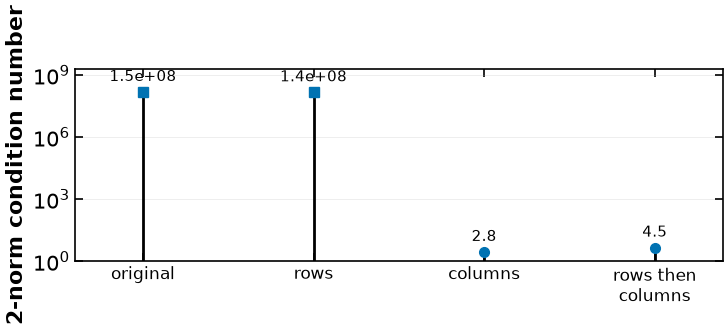

In [30]:
fig, ax = plt.subplots(figsize=(7.6,2.8))
rows = results["cases"]
for i,row in enumerate(rows):
    ax.plot([i,i],[1,row["condition_2"]],color="black",linestyle="-",linewidth=2)
    ax.plot(i,row["condition_2"],marker="s" if i<2 else "o",color="#0072B2",linestyle="none",ms=7)
    ax.annotate(f'{row["condition_2"]:.2g}', (i,row["condition_2"]),
                xytext=(0,8),textcoords="offset points",ha="center",fontsize=11)
ax.set_yscale("log")
ax.set(xticks=range(4),xticklabels=["original","rows","columns","rows then\ncolumns"],
       ylabel="2-norm condition number",ylim=(1,2e9),xlim=(-.4,3.4))
ax.tick_params(axis="x",labelsize=12)
ax.grid(axis="y",which="major",alpha=.25)
fig.tight_layout()
helper.save_figure(fig,"ctx-scaling-actual",quiet=True)
plt.show()

The original and recovered solution is $(10^5,10^{-3},1)^\mathsf T$. Column scaling gives coordinates $(1,1,1)^\mathsf T$; row-then-column scaling gives approximately $(.002,.001,.005)^\mathsf T$. The much smaller coordinates in the combined case are not different physical decisions. The 2-norm condition numbers are approximately $1.49\cdot10^8$, $1.44\cdot10^8$, $2.79$, and $4.50$. They compare conditioning of four represented systems; check the original residual after reversing the transformation. Choosing scales needs characteristic units and model knowledge, not only a blind largest-entry rule. Near dependent equations can remain ill conditioned after unit scaling.